# Exploratory Data Analysis

#### Objective

The objective is to predict the customer's rating score to help the company to assign deliveries to the best driver to achieve better overall ratings.


In [100]:
#import modules
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
import sqlite3

In [101]:
# Connect to database and read data into DataFrame
conn = sqlite3.connect('data/delivery.db')

# Read entire table of deliveries into DataFrame
df_deliveries = pd.read_sql_query("SELECT * FROM deliveries", conn)
print(df_deliveries.head())
print(f"DataFrame shape: {df_deliveries.shape}")

# Read entire table of feedback into DataFrame
df_cleanededback = pd.read_sql_query("SELECT * FROM feedback", conn)
print(df_cleanededback.head())
print(f"DataFrame shape: {df_cleanededback.shape}")

# Close connection
conn.close()

   delivery_id branch client_id            booking_datetime  \
0  D2026000000  North     C0000  2026-01-17 16:10:11.419632   
1  D2026000001  North     C0007  2025-12-06 15:33:02.496777   
2  D2026000002   East     C0000  2026-04-20 16:32:08.934038   
3  D2026000003   East     C0002  2026-05-11 12:15:01.850095   
4  D2026000004  North     C0009  2026-05-20 14:32:47.616722   

              pickup_datetime  promised_delivery_datetime  \
0  2026-01-17 18:14:42.141079  2026-01-18 00:10:11.419632   
1  2025-12-06 16:11:03.931680  2025-12-06 19:33:02.496777   
2  2026-04-20 19:54:14.157180  2026-04-21 00:32:08.934038   
3  2026-05-11 14:44:34.713623  2026-05-11 20:15:01.850095   
4  2026-05-20 15:50:24.743132  2026-05-20 18:32:47.616722   

            delivery_datetime  distance_km parcel_weight_kg parcel_value_sgd  \
0  2026-01-17 23:58:29.106853         5.86            0.585           102.05   
1  2025-12-06 18:53:45.937422         3.10            3.292           105.17   
2  2026-04-21 

## Preliminary Data Exploration

In [102]:
# Initial data preparation to get our dataframe for EDA
# Merge deliveries and feedback DataFrames on delivery_id, keeping only rows with matching delivery_id in both DataFrames
df = df_cleanededback.merge(df_deliveries, on='delivery_id', how='inner')

df.head()

,feedback_id,delivery_id,rating,comment,feedback_datetime,branch,client_id,booking_datetime,pickup_datetime,promised_delivery_datetime,...,parcel_weight_kg,parcel_value_sgd,parcel_category,delivery_priority,num_stops_on_route,driver_id,driver_experience_months,vehicle_type,payment_method,recipient_postal_code
0,F01000000,D2026000001,5.0,"On time as always, thanks! Driver very polite,...",2025-12-07 02:17:46.889241,North,C0007,2025-12-06 15:33:02.496777,2025-12-06 16:11:03.931680,2025-12-06 19:33:02.496777,...,3.292,105.17,standard,Express,None,DRV0087,33.0,van,cod,73
1,F01000001,D2026000003,3.0,Delivery was acceptable.,2026-05-12 11:00:52.289329,East,C0002,2026-05-11 12:15:01.850095,2026-05-11 14:44:34.713623,2026-05-11 20:15:01.850095,...,2.163,71.8,fragile,Standard,90.0,DRV0109,9.0,van,prepaid,49
2,F01000002,D2026000011,5.0,"Great experience, no complaints.",2026-04-11 08:19:49.177079,West,C0003,2026-04-10 15:04:37.406631,2026-04-10 16:25:20.594072,2026-04-10 23:04:37.406631,...,1.061,186.63,standard,Standard,35.0,DRV0081,24.0,bike,prepaid,23
3,F01000003,D2026000012,5.0,,2025-12-31 11:57:23.657124,North,C0044,2025-12-30 17:41:52.204675,2025-12-30 20:36:25.912043,2025-12-31 01:41:52.204675,...,0.315,72.09,standard,Standard,50.0,DRV0125,8.0,bike,prepaid,76
4,F01000004,D2026000013,4.0,,2026-02-24 04:52:01.214870,Central,C0001,2026-02-23 16:11:42.280341,2026-02-23 18:55:33.797727,2026-02-24 00:11:42.280341,...,6.307,34.35,fragile,Standard,28.0,DRV0052,15.0,truck,prepaid,01


In [103]:
df.shape

(55267, 22)

In [104]:
df.describe()

,rating,distance_km
count,53007.000000,55267.000000
mean,4.299828,5.842213
std,0.985250,3.459460
min,1.000000,0.490000
25%,4.000000,3.460000
50%,5.000000,5.020000
75%,5.000000,7.280000
max,5.000000,30.000000


In [105]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55267 entries, 0 to 55266
Data columns (total 22 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   feedback_id                 55267 non-null  object 
 1   delivery_id                 55267 non-null  object 
 2   rating                      53007 non-null  float64
 3   comment                     53067 non-null  object 
 4   feedback_datetime           55267 non-null  object 
 5   branch                      55267 non-null  object 
 6   client_id                   55267 non-null  object 
 7   booking_datetime            55267 non-null  object 
 8   pickup_datetime             55267 non-null  object 
 9   promised_delivery_datetime  55267 non-null  object 
 10  delivery_datetime           55267 non-null  object 
 11  distance_km                 55267 non-null  float64
 12  parcel_weight_kg            53130 non-null  object 
 13  parcel_value_sgd            530

In [106]:
df.isnull().sum()

feedback_id                      0
delivery_id                      0
rating                        2260
comment                       2200
feedback_datetime                0
branch                           0
client_id                        0
booking_datetime                 0
pickup_datetime                  0
promised_delivery_datetime       0
delivery_datetime                0
distance_km                      0
parcel_weight_kg              2137
parcel_value_sgd              2187
parcel_category                  0
delivery_priority                0
num_stops_on_route            2242
driver_id                        0
driver_experience_months      2145
vehicle_type                  2251
payment_method                2214
recipient_postal_code         2176
dtype: int64

In [107]:
print(f"Delivery IDs duplicated: {df['delivery_id'].duplicated().sum()}")
duplicated_df = df[df["delivery_id"].duplicated(keep=False)].sort_values(by="delivery_id")
duplicated_df.head(25)

Delivery IDs duplicated: 568


,feedback_id,delivery_id,rating,comment,feedback_datetime,branch,client_id,booking_datetime,pickup_datetime,promised_delivery_datetime,...,parcel_weight_kg,parcel_value_sgd,parcel_category,delivery_priority,num_stops_on_route,driver_id,driver_experience_months,vehicle_type,payment_method,recipient_postal_code
173,F01000173,D2026000494,5.0,Polite and professional driver.,2026-05-25 21:50:23.155392,North,C0000,2026-05-25 11:43:22.590744,2026-05-25 12:58:27.441491,2026-05-25 15:43:22.590744,...,1.518,208.6,standard,Express,45.0,DRV0035,-1.0,bike,prepaid,57
55226,F01000173,D2026000494,5.0,Polite and professional driver.,2026-05-25 21:50:23.155392,North,C0000,2026-05-25 11:43:22.590744,2026-05-25 12:58:27.441491,2026-05-25 15:43:22.590744,...,1.518,208.6,standard,Express,45.0,DRV0035,-1.0,bike,prepaid,57
355,F01000355,D2026000998,1.0,Driver was extremely unprofessional.,2026-04-18 03:43:23.726061,East,C0014,2026-04-17 10:30:00.946949,2026-04-17 13:22:53.026192,2026-04-17 18:30:00.946949,...,1.798,66.9,standard,Standard,58.0,DRV0165,7.0,bike,None,52
356,F01000355,D2026000998,1.0,Driver was extremely unprofessional.,2026-04-18 03:43:23.726061,East,C0014,2026-04-17 10:30:00.946949,2026-04-17 13:22:53.026192,2026-04-17 18:30:00.946949,...,1.798,66.9,standard,Standard,58.0,DRV0165,7.0,bike,None,52
364,F01000363,D2026001017,5.0,Driver was very friendly and on time.,2026-03-14 21:49:57.377388,West,C0002,2026-03-14 12:29:06.915649,2026-03-14 15:09:51.002796,2026-03-14 20:29:06.915649,...,2.279,55.75,standard,Standard,46.0,DRV0125,None,truck,prepaid,None
55096,F01000363,D2026001017,5.0,Driver was very friendly and on time.,2026-03-14 21:49:57.377388,West,C0002,2026-03-14 12:29:06.915649,2026-03-14 15:09:51.002796,2026-03-14 20:29:06.915649,...,2.279,55.75,standard,Standard,46.0,DRV0125,None,truck,prepaid,None
55196,F01000502,D2026001414,3.0,,2026-05-26 07:25:46.825557,East,C0000,2026-05-25 15:49:39.568171,2026-05-25 18:02:19.921455,2026-05-25 23:49:39.568171,...,1.444,43.85,standard,Standard,40.0,DRV0155,10.0,bike,prepaid,52
503,F01000502,D2026001414,3.0,,2026-05-26 07:25:46.825557,East,C0000,2026-05-25 15:49:39.568171,2026-05-25 18:02:19.921455,2026-05-25 23:49:39.568171,...,1.444,43.85,standard,Standard,40.0,DRV0155,10.0,bike,prepaid,52
55121,F01000520,D2026001457,4.0,"Reasonable speed, package was fine.",2026-03-17 23:54:09.952561,East,C0005,2026-03-17 13:15:16.571531,2026-03-17 16:53:20.550418,2026-03-17 21:15:16.571531,...,2.456,185.28,fragile,Standard,56.0,DRV0182,2.0,None,prepaid,49
521,F01000520,D2026001457,4.0,"Reasonable speed, package was fine.",2026-03-17 23:54:09.952561,East,C0005,2026-03-17 13:15:16.571531,2026-03-17 16:53:20.550418,2026-03-17 21:15:16.571531,...,2.456,185.28,fragile,Standard,56.0,DRV0182,2.0,None,prepaid,49


In [108]:
duplicated_df = duplicated_df.sort_values(by="rating", ascending=True)
duplicated_df.head(25)

,feedback_id,delivery_id,rating,comment,feedback_datetime,branch,client_id,booking_datetime,pickup_datetime,promised_delivery_datetime,...,parcel_weight_kg,parcel_value_sgd,parcel_category,delivery_priority,num_stops_on_route,driver_id,driver_experience_months,vehicle_type,payment_method,recipient_postal_code
55027,F01002631,D2026007037,1.0,Package was broken when I opened it. Late agai...,2026-05-16 11:51:11.669858,East,C0001,2026-05-15 15:28:12.986290,2026-05-15 16:48:28.564268,2026-05-15 23:28:12.986290,...,3.367,175.54,oversized,Standard,53.0,DRV0104,3.0,truck,prepaid,48
10608,F01010547,D2026028693,1.0,Package arrived damaged! Promised window was c...,2026-01-18 22:21:47.125364,West,C0017,2026-01-18 11:15:07.871718,2026-01-18 12:56:07.024978,2026-01-18 19:15:07.871718,...,0.379,54.45,oversized,Standard,38.0,DRV0137,6.0,bike,prepaid,63
55140,F01007030,D2026019105,1.0,Package was broken when I opened it. Late agai...,2026-05-16 00:44:27.798268,East,C0005,2026-05-15 13:11:35.617356,2026-05-15 16:11:11.665056,2026-05-15 21:11:35.617356,...,0.561,150.24,standard,Standard,42.0,DRV0010,6.0,bike,prepaid,51
7076,F01007030,D2026019105,1.0,Package was broken when I opened it. Late agai...,2026-05-16 00:44:27.798268,East,C0005,2026-05-15 13:11:35.617356,2026-05-15 16:11:11.665056,2026-05-15 21:11:35.617356,...,0.561,150.24,standard,Standard,42.0,DRV0010,6.0,bike,prepaid,51
6489,F01006449,D2026017603,1.0,,2026-03-15 01:24:38.673649,Central,C0007,2026-03-14 14:31:04.805718,2026-03-14 14:57:17.810651,2026-03-14 18:31:04.805718,...,3.043,76.03,standard,Express,39.0,DRV0136,6.0,van,prepaid,30
6490,F01006449,D2026017603,1.0,,2026-03-15 01:24:38.673649,Central,C0007,2026-03-14 14:31:04.805718,2026-03-14 14:57:17.810651,2026-03-14 18:31:04.805718,...,3.043,76.03,standard,Express,39.0,DRV0136,6.0,van,prepaid,30
34933,F01034736,D2026094948,1.0,,2026-05-07 18:48:18.893943,West,C0013,2026-05-07 12:09:59.952445,2026-05-07 12:31:42.032463,2026-05-07 14:09:59.952445,...,0.581,59.31,standard,Premium,57.0,DRV0082,5.0,van,prepaid,65
34932,F01034736,D2026094948,1.0,,2026-05-07 18:48:18.893943,West,C0013,2026-05-07 12:09:59.952445,2026-05-07 12:31:42.032463,2026-05-07 14:09:59.952445,...,0.581,59.31,standard,Premium,57.0,DRV0082,5.0,van,prepaid,65
55088,F01046004,D2026125759,1.0,"Terrible experience, will not use again. Fragi...",2026-03-24 04:45:47.838580,North,C0003,2026-03-23 15:43:12.817568,2026-03-23 17:50:11.836907,2026-03-23 23:43:12.817568,...,0.397,46.15,fragile,Standard,32.0,DRV0141,9.0,bike,prepaid,57
41730,F01041494,D2026113304,1.0,Package arrived damaged! The driver came hours...,2026-05-15 05:10:42.609760,Central,C0000,2026-05-14 12:14:10.426155,2026-05-14 16:31:29.103709,2026-05-14 20:14:10.426155,...,2.862,36.39,fragile,Standard,49.0,DRV0040,17.0,van,prepaid,22


In [109]:
print(df.nunique())

feedback_id                   54699
delivery_id                   54699
rating                            5
comment                         878
feedback_datetime             54699
branch                            8
client_id                        60
booking_datetime              54699
pickup_datetime               54699
promised_delivery_datetime    54699
delivery_datetime             54699
distance_km                    2074
parcel_weight_kg               8073
parcel_value_sgd              18409
parcel_category                   8
delivery_priority                 4
num_stops_on_route               87
driver_id                       200
driver_experience_months        122
vehicle_type                      6
payment_method                    2
recipient_postal_code            37
dtype: int64


In [110]:
print("Check Categorical and Boolean Column unique values:")
print(f"{df.rating.name}:{df.rating.unique()}")
print(f"{df.branch.name}:{df.branch.unique()}")
print(f"{df.parcel_category.name}:{df.parcel_category.unique()}")
print(f"{df.delivery_priority.name}:{df.delivery_priority.unique()}")
print(f"{df.vehicle_type.name}:{df.vehicle_type.unique()}")
print(f"{df.payment_method.name}:{df.payment_method.unique()}")
print(f"{df.driver_experience_months.name}:{df.driver_experience_months.unique()}")

Check Categorical and Boolean Column unique values:
rating:[ 5.  3.  4.  1.  2. nan]
branch:['North' 'East' 'West' 'Central' 'Cnetral' 'EAST' 'west ' 'Noth']
parcel_category:['standard' 'fragile' 'oversized' 'refrigerated' 'over-sized' 'Standard'
 'Fragile ' 'refrig.']
delivery_priority:['Express' 'Standard' 'Premium' 'VIP']
vehicle_type:['van' 'bike' 'truck' 'VAN' None 'truck ' 'Bike']
payment_method:['cod' 'prepaid' None]
driver_experience_months:['33.0' '9.0' '24.0' '8.0' '15.0' '31.0' '18.0' '11.0' '5.0' '47.0' '3.0'
 '12.0' '14.0' '2.0' '10.0' '48.0' '16.0' '51.0' '25.0' '6.0' None '29.0'
 '36.0' '0.0' '13.0' '7.0' '22.0' '21.0' '4.0' '85.0' '62.0' '26.0' '19.0'
 '67.0' '17.0' '1.0' '90.0' '43.0' '20.0' '30.0' '-1.0' '23.0' '88.0'
 '37.0' '50.0' '57.0' '28.0' '52.0' '34.0' '41.0' '27.0' '93.0' '44.0'
 '102.0' '56.0' '40.0' '55.0' '32.0' '68.0' '38.0' '39.0' '42.0' '92.0'
 '65.0' '58.0' '63.0' '45.0' '76.0' '53.0' '60.0' '83.0' '35.0' '49.0'
 '107.0' '120.0' '78.0' '59.0' '66.0' '7

#### Data Structure, Assumptions and Anomalies

* There were two tables in the dataframe so I merged it to streamline the EDA for one dataframe.
* The merged dataset has 55267 rows and 22 columns. The merge was performed using inner merge as we only want to keep data where both tables have values on delivery_id.
* There are null values for rating and rows with null values will be dropped as this is the prediction target and cannot be null for training.
* There are duplicated values for rating and we will keep the first occurance and drop duplicates.
* The comment column has content that is not consistent from customer to customer and most have little value as they do not explicitly list the reason for their rating for both positive and negative comments. This feature is good for human interpretation but not useful for training the model as it may result in inaccuracies in prediction so the column will be dropped.
* recipient_postal_code will be useful for future implementation of actual route distance calculations using external map APIs but we will not be using it for this iteration of the model construction to keep the implementation simple so it will be dropped.
* Rows with null values for parcel_weight_kg, parcel_value_sgd, num_stops_on_route, payment_method and vehicle_type will be dropped as we are unable to derive a value for it.
* Null and negative driver_experience_months can be filled in with other entries that have the same driver_id, remaining null values will be dropped.
* The string values for categories in branch, parcel_category and vehicle_type have spelling and formatting errors and will require renaming.
* parcel_weight_kd, parcel_value_sgd, num_stops_on_route, driver_experience_months needs to be converted from object to numeric.
* feedback_datetime, booking_datetime, pickup_datetime, promised_delivery_datetime, delivery_datetime needst to be converted from object to datetime.
* id columns will be dropped as they do not contribute to model training.

## Data Cleaning

In [111]:
df_cleaned = df.copy()

# Fix inconsistent categorical/boolean values
df_cleaned['branch'] = df_cleaned['branch'].replace({'EAST': 'East', 'Cnetral': 'Central', 'west ': 'West', 'Noth': 'North'})
df_cleaned['parcel_category'] = df_cleaned['parcel_category'].replace({'Fragile ': 'fragile', 'Standard': 'standard', 'over-sized': 'oversized', 'refrig.': 'refrigerated'})
df_cleaned['vehicle_type'] = df_cleaned['vehicle_type'].replace({'VAN': 'van', 'Bike': 'bike', 'truck ': 'truck'})

# parcel_weight_kg, parcel_value_sgd, num_stops_on_route, driver_experience_months will be converted from object to numeric.
df_cleaned['parcel_weight_kg'] = pd.to_numeric(df_cleaned['parcel_weight_kg'], errors='coerce')
df_cleaned['parcel_value_sgd'] = pd.to_numeric(df_cleaned['parcel_value_sgd'], errors='coerce')
df_cleaned['num_stops_on_route'] = pd.to_numeric(df_cleaned['num_stops_on_route'], errors='coerce')
df_cleaned['driver_experience_months'] = pd.to_numeric(df_cleaned['driver_experience_months'], errors='coerce')

# Convert datetime columns from object to datetime.
datetime_cols = ['booking_datetime', 'pickup_datetime', 'feedback_datetime', 
                 'promised_delivery_datetime', 'delivery_datetime']
for col in datetime_cols:
    df_cleaned[col] = pd.to_datetime(df_cleaned[col], errors='coerce')

print(df_cleaned.info())

# Drop delivery_id duplicates, assuming first entry to be correct by using keep="first"
df_cleaned = df_cleaned.sort_index()
df_cleaned = df_cleaned.drop_duplicates(subset="delivery_id", keep="first")
print(df_cleaned.shape)

# Drop rows with missing values in the rating column, as these are our target variable and cannot be imputed
df_cleaned = df_cleaned.dropna(subset=["rating"])
print(df_cleaned.shape)

# Drop comment column as it is not relevant for our analysis and has a high number of unique values, making it unsuitable for encoding
df_cleaned = df_cleaned.drop(columns=["comment"])
print(df_cleaned.shape)

# Drop recipient_postal_code column as it will not be used for this iteration of the model
df_cleaned = df_cleaned.drop(columns=["recipient_postal_code"])
print(df_cleaned.shape)

# Rows with null values for parcel_weight_kg, parcel_value_sgd, num_stops_on_route, payment_method and vehicle_type will be dropped as we are unable to derive a value for it
# Replace negative values for parcel_weight_kg, parcel_value_sgd and num_stops_on_route with NaN to treat them as missing values
df_cleaned['parcel_weight_kg'] = df_cleaned['parcel_weight_kg'].apply(lambda x: np.nan if x < 0 else x)
df_cleaned['parcel_value_sgd'] = df_cleaned['parcel_value_sgd'].apply(lambda x: np.nan if x < 0 else x)
df_cleaned['num_stops_on_route'] = df_cleaned['num_stops_on_route'].apply(lambda x: np.nan if x < 0 else x)
df_cleaned = df_cleaned.dropna(subset=["parcel_weight_kg", "parcel_value_sgd", "num_stops_on_route", "payment_method", "vehicle_type"])
print(df_cleaned.shape)

# Handle null and negative driver_experience_months values
print("\n--- Handling null and negative driver_experience_months ---")
# Replace negative values with NaN to treat them as missing values
df_cleaned['driver_experience_months'] = df_cleaned['driver_experience_months'].apply(lambda x: np.nan if x < 0 else x)
print(f"Null values before processing: {df_cleaned['driver_experience_months'].isnull().sum()}")
# Fill null values using other entries with same driver_id
driver_experience_map = df_cleaned.groupby('driver_id')['driver_experience_months'].transform('mean')
df_cleaned['driver_experience_months'] = df_cleaned['driver_experience_months'].fillna(driver_experience_map)
# Drop any remaining null values
df_cleaned = df_cleaned.dropna(subset=['driver_experience_months'])
print(f"Null values after processing: {df_cleaned['driver_experience_months'].isnull().sum()}")

print(f"Final DataFrame shape: {df_cleaned.shape}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55267 entries, 0 to 55266
Data columns (total 22 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   feedback_id                 55267 non-null  object        
 1   delivery_id                 55267 non-null  object        
 2   rating                      53007 non-null  float64       
 3   comment                     53067 non-null  object        
 4   feedback_datetime           55267 non-null  datetime64[ns]
 5   branch                      55267 non-null  object        
 6   client_id                   55267 non-null  object        
 7   booking_datetime            55267 non-null  datetime64[ns]
 8   pickup_datetime             55267 non-null  datetime64[ns]
 9   promised_delivery_datetime  55267 non-null  datetime64[ns]
 10  delivery_datetime           55267 non-null  datetime64[ns]
 11  distance_km                 55267 non-null  float64   

## Feature Engineering

In [112]:
# FEATURE 1: Day of Week & Hour from delivery_datetime
df_cleaned['delivery_day_of_week'] = df_cleaned['promised_delivery_datetime'].dt.dayofweek
df_cleaned['delivery_hour'] = df_cleaned['promised_delivery_datetime'].dt.hour

# FEATURE 2: Driver Daily Accumulated Distance
# Extract date from delivery_datetime for grouping by driver+day
df_cleaned['delivery_date'] = df_cleaned['delivery_datetime'].dt.date
# Calculate accumulated distance per driver per day
# This captures how "busy" or fatigued a driver is that day
driver_daily_distance = df_cleaned.groupby(['driver_id', 'delivery_date'])['distance_km'].transform('sum')
df_cleaned['driver_daily_total_distance_km'] = driver_daily_distance

# FEATURE 3: Minutes Before Late (time left before delivery is considered late, negative if already late)
df_cleaned['minutes_before_late'] = (
    df_cleaned['promised_delivery_datetime'] - df_cleaned['booking_datetime']
).dt.total_seconds() / 60

# FEATURE 4: Pickup hour (when driver picks up from depot)
df_cleaned['pickup_hour'] = df_cleaned['pickup_datetime'].dt.hour

# FEATURE 5: Is weekend
df_cleaned['is_weekend'] = df_cleaned['delivery_day_of_week'].isin([5, 6]).astype(int)

# FEATURE 6: Is peak hour (8-9am morning commute, 12-1pm lunch rush, 6-8pm evening end work commute)
df_cleaned['is_peak_hour'] = df_cleaned['delivery_hour'].isin([8, 12, 18, 19]).astype(int)

# FEATURE 7: Driver median minutes taken to pickup from booking (proxy for driver efficiency)
df_cleaned['minutes_since_booking'] = (df_cleaned['pickup_datetime'] - df_cleaned['booking_datetime']).dt.total_seconds() / 60
driver_med_pickup_time = df_cleaned.groupby('driver_id')['minutes_since_booking'].transform('median')
df_cleaned['driver_med_minutes_to_pickup'] = driver_med_pickup_time

df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 40854 entries, 1 to 54992
Data columns (total 30 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   feedback_id                     40854 non-null  object        
 1   delivery_id                     40854 non-null  object        
 2   rating                          40854 non-null  float64       
 3   feedback_datetime               40854 non-null  datetime64[ns]
 4   branch                          40854 non-null  object        
 5   client_id                       40854 non-null  object        
 6   booking_datetime                40854 non-null  datetime64[ns]
 7   pickup_datetime                 40854 non-null  datetime64[ns]
 8   promised_delivery_datetime      40854 non-null  datetime64[ns]
 9   delivery_datetime               40854 non-null  datetime64[ns]
 10  distance_km                     40854 non-null  float64       
 11  parcel_

## Univariate Analysis

#### Visualising Distributions

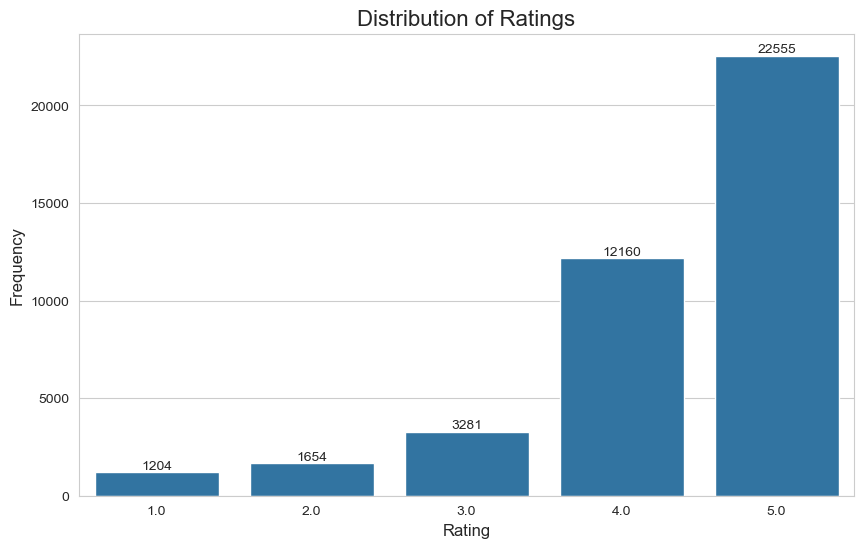

In [113]:
# Displaying the distribution of the target variable (rating) using a bar plot to show frequency of each rating score
plt.figure(figsize=(10, 6))
rating_counts = df_cleaned['rating'].value_counts().sort_index()
sns.barplot(x=rating_counts.index, y=rating_counts.values, color='tab:blue')
plt.title('Distribution of Ratings', fontsize=16)
plt.xlabel('Rating', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.xticks(rotation=0)

# add value labels on top of each bar
for index, value in enumerate(rating_counts.values):
    plt.text(index, value, str(value), ha='center', va='bottom')

plt.show()

**Interpreting Trends from Ratings Distribution**

From the distribution of ratings, I can see that it is heavily left-skewed and imbalanced towards high ratings.
* 5 is the overwhelming mode and has 22555 occurances.
* 4 is the second most frequesnt with 12160 occurances.
* 5 and 4 combines to make the bulk of the dataset.

The distribution has a long left tail.
* For 3, 2 and 1, there is a drastic drop in frequency, 3281, 1654 and 1204 respestively.

I will need to perform resampling for the training data to help the model learn patterns from underrepresented rating values 3 and below.
I will need to perform stratified splitting of the data to ensure equal proportion of low ratings so the test set remains realistic.

In [114]:
df_cleaned.describe()

,rating,feedback_datetime,booking_datetime,pickup_datetime,promised_delivery_datetime,delivery_datetime,distance_km,parcel_weight_kg,parcel_value_sgd,num_stops_on_route,driver_experience_months,delivery_day_of_week,delivery_hour,driver_daily_total_distance_km,minutes_before_late,pickup_hour,is_weekend,is_peak_hour,minutes_since_booking,driver_med_minutes_to_pickup
count,40854.000000,40854,40854,40854,40854,40854,40854.000000,40854.000000,40854.000000,40854.000000,40854.000000,40854.000000,40854.000000,40854.000000,40854.000000,40854.000000,40854.000000,40854.000000,40854.000000,40854.000000
mean,4.302394,2026-02-28 04:14:49.865624320,2026-02-27 14:16:25.352554240,2026-02-27 16:11:51.829340416,2026-02-27 20:10:05.032389888,2026-02-27 20:12:00.834829824,5.856561,2.245271,82.286835,45.654771,17.536130,2.358423,16.825256,13.533071,353.661331,15.423704,0.099280,0.223087,115.441280,101.697872
min,1.000000,2025-11-28 12:20:15.496623,2025-11-28 09:36:09.702003,2025-11-28 10:18:59.463506,2025-11-28 11:43:07.442364,2025-11-28 11:21:08.858120,0.490000,0.050000,3.000000,5.000000,0.000000,0.000000,0.000000,0.500000,60.000000,0.000000,0.000000,0.000000,6.026246,80.382018
25%,4.000000,2026-01-14 03:06:56.125291008,2026-01-13 14:05:50.222968064,2026-01-13 16:08:45.207052032,2026-01-13 20:28:59.076899328,2026-01-13 20:16:39.109719040,3.480000,0.816000,21.480000,33.000000,7.000000,1.000000,16.000000,6.910000,240.000000,14.000000,0.000000,0.000000,57.054443,96.934348
50%,5.000000,2026-02-28 01:18:37.298824960,2026-02-27 13:20:00.385263872,2026-02-27 15:03:37.584713984,2026-02-27 19:17:47.474357504,2026-02-27 19:01:49.963284480,5.030000,1.495000,44.700000,44.000000,13.000000,2.000000,19.000000,11.770000,480.000000,15.000000,0.000000,0.000000,101.494172,101.778603
75%,5.000000,2026-04-14 20:50:03.087520768,2026-04-14 11:34:42.630334208,2026-04-14 13:07:48.818605056,2026-04-14 16:00:24.890337792,2026-04-14 16:03:43.375094784,7.300000,2.761000,94.890000,56.000000,21.000000,4.000000,21.000000,18.140000,480.000000,17.000000,0.000000,0.000000,168.374503,106.985081
max,5.000000,2026-05-29 12:50:00.532217,2026-05-27 18:28:23.863256,2026-05-27 22:43:48.751991,2026-05-28 02:28:23.863256,2026-05-28 06:26:18.454618,30.000000,30.000000,3308.210000,90.000000,120.000000,6.000000,23.000000,74.230000,480.000000,23.000000,1.000000,1.000000,625.090641,116.001318
std,0.983951,NaN,NaN,NaN,NaN,NaN,3.465526,2.460018,120.212897,17.137518,15.781202,1.686494,6.291754,8.725607,150.485286,2.378436,0.299042,0.416321,71.596253,7.398749


In [115]:
df_cleaned.minutes_before_late.unique()

array([480., 120., 240.,  60.])

In [125]:
# Create Bins for continuous features for better visualisation in plots
BINNING_CONFIG = {
    "parcel_weight_kg": {"bins": [0, 1, 2, 3, 4, 5, np.inf], "labels": ['0-1', '1-2', '2-3', '3-4', '4-5', '5+']},
    "parcel_value_sgd": {"bins": [0, 25, 50, 75, 100, 125, 150, np.inf], "labels": ['0-25', '26-50', '51-75', '76-100', '101-125', '126-150', '151+']},
    "minutes_before_late": {"bins": [0, 60, 120, 240, 480], "labels": ['0-60', '61-120', '120-240', '241-480']},
    "num_stops_on_route": {"bins": [0, 10, 20, 30, 40, 50, 60, 70, 80, np.inf], "labels": ['0-10', '11-20', '21-30', '31-40', '41-50', '51-60', '61-70', '70-80', '80+']},
    "driver_experience_months": {"bins": [0, 12, 24, 36, 48, 60, np.inf], "labels": ['0-12', '13-24', '25-36', '37-48', '49-60', '60+']},
    "driver_daily_total_distance_km": {"bins": [0, 5, 10, 15, 20, 25, 30, np.inf], "labels": ['0-5', '6-10', '11-15', '16-20', '21-25', '26-30', '30+']},
    "driver_med_minutes_to_pickup": {"bins": [80, 90, 100, 110, 120], "labels": ['80-90', '91-100', '101-110', '111-120']},
    "distance_km": {"bins": [0, 5, 10, 15, 20, 25, 30], "labels": ['0-5', '6-10', '11-15', '16-20', '21-25', '26-30']}
}

# Create binned columns for the specified features
for feature, config in BINNING_CONFIG.items():
    df_cleaned[f"binned_{feature}"] = pd.cut(df_cleaned[feature], bins=config["bins"], labels=config["labels"])

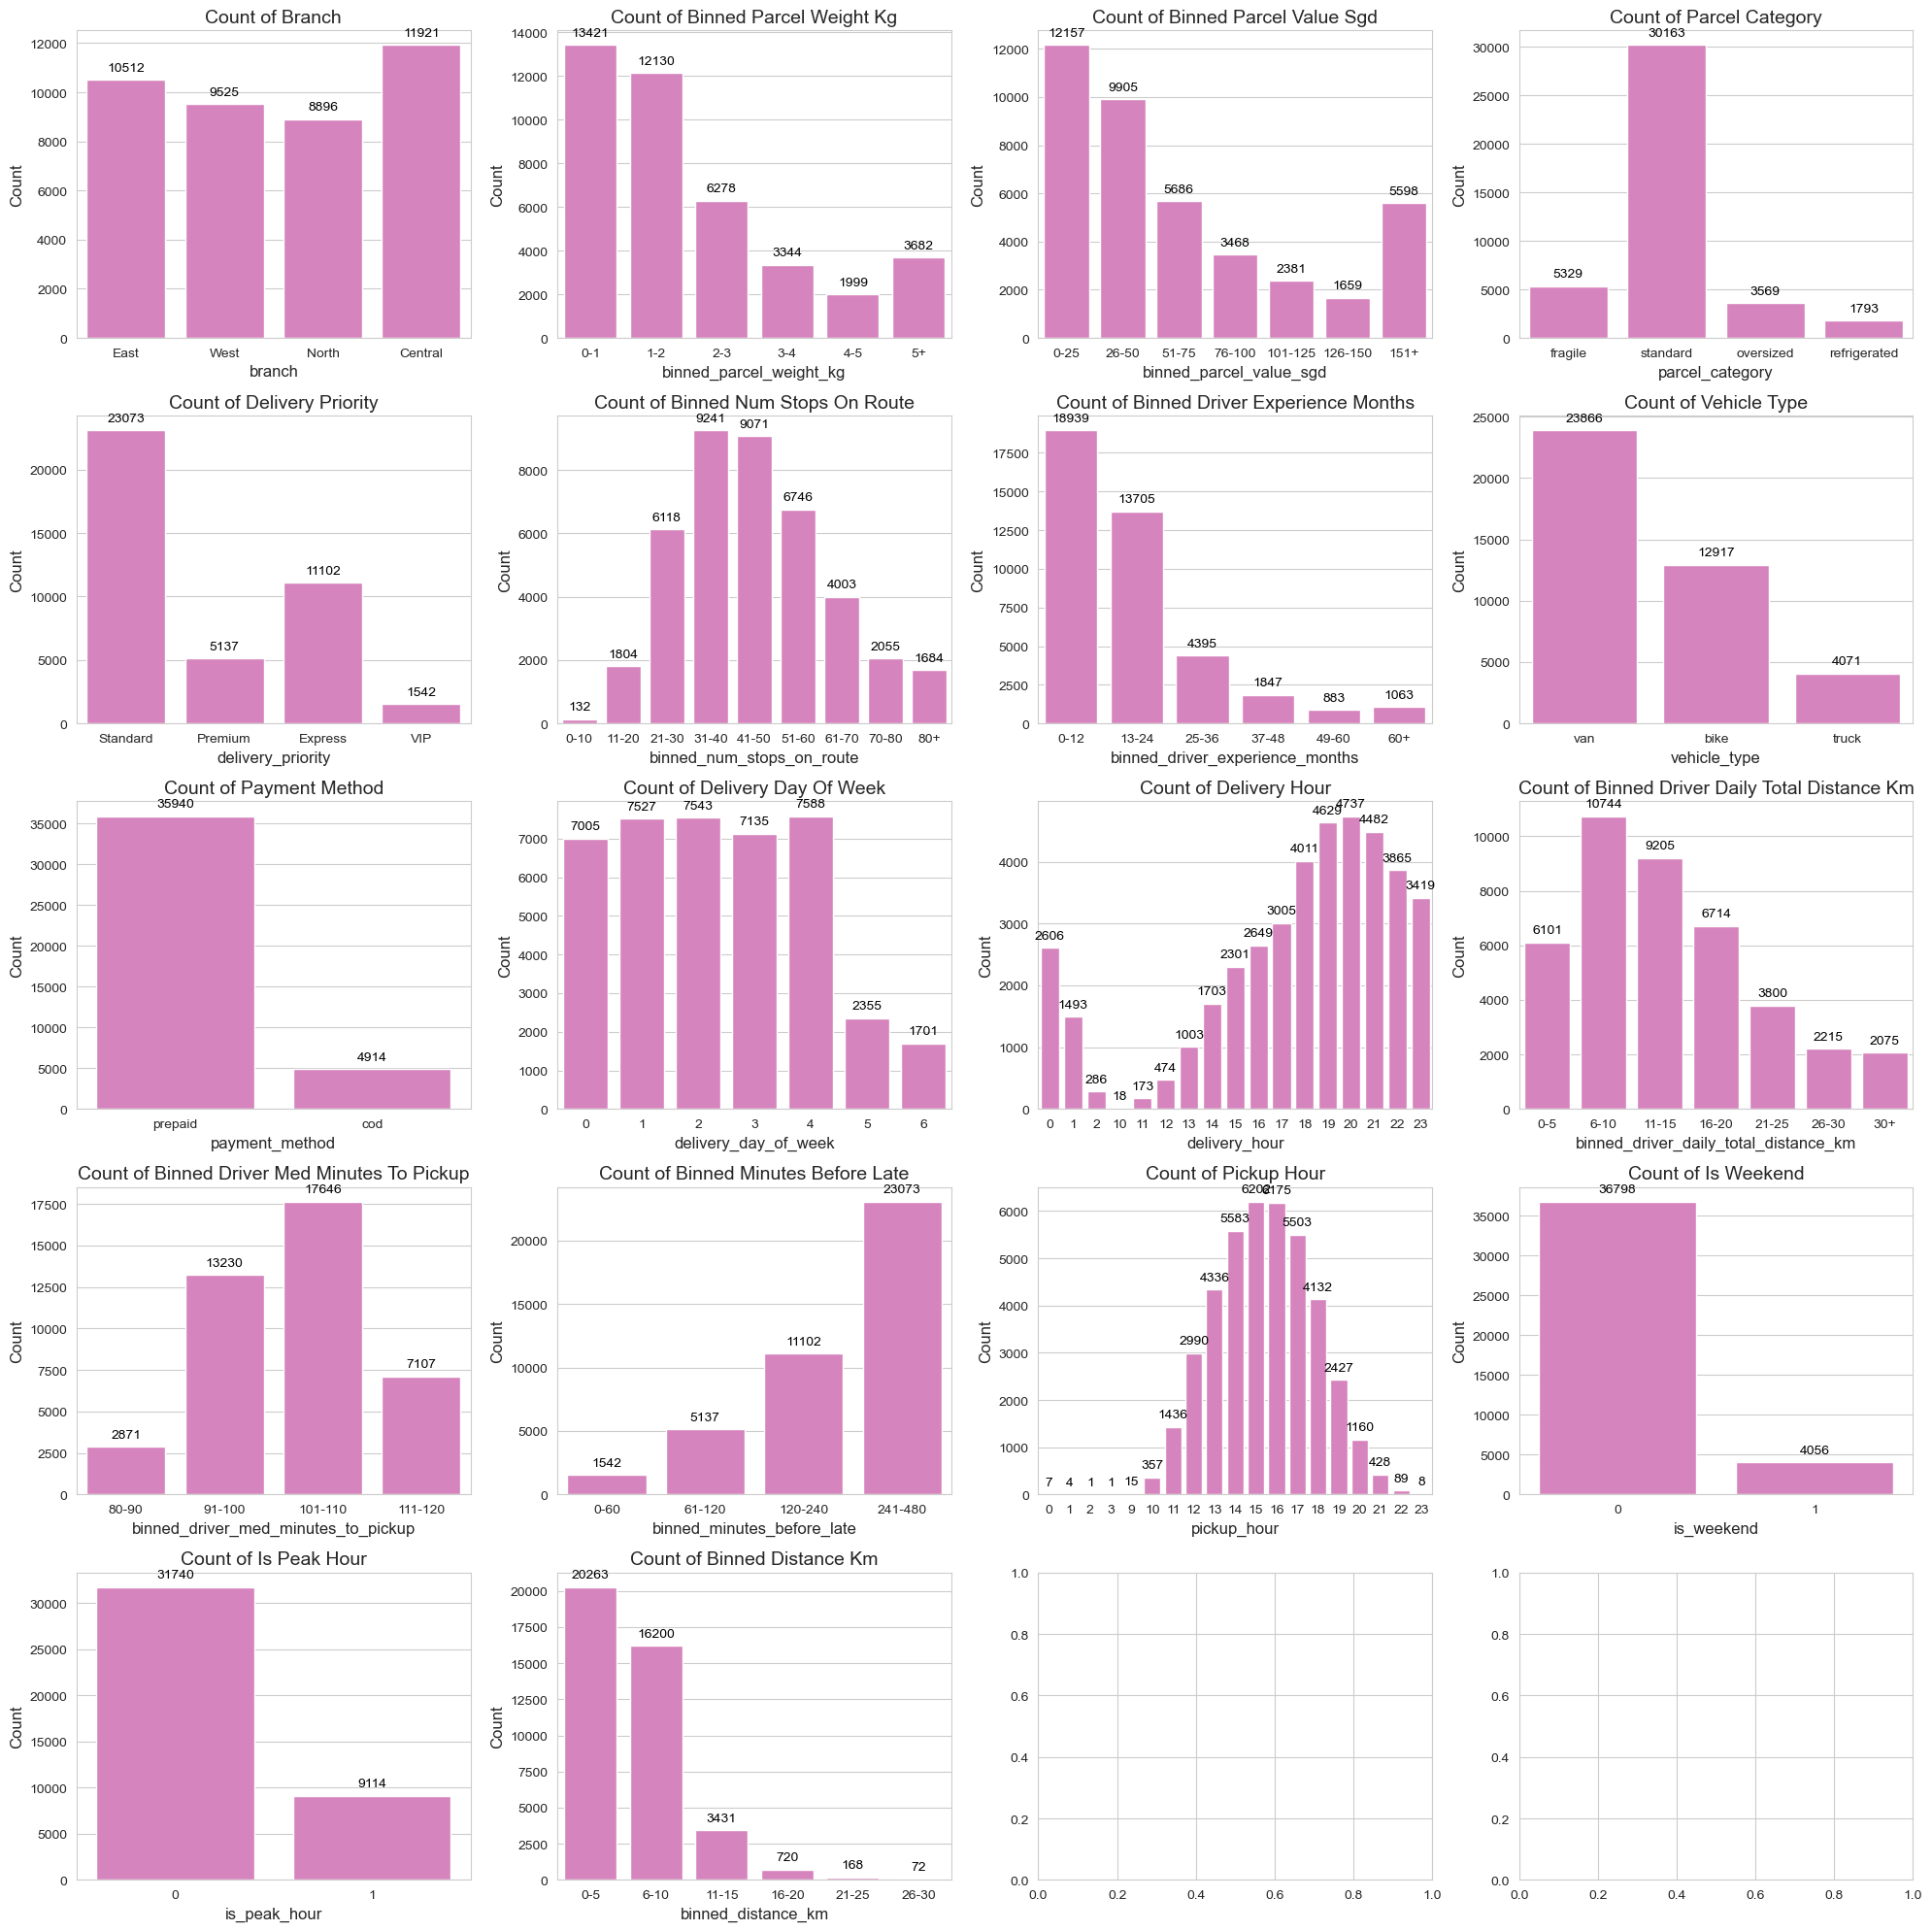

In [126]:
# Set the style
sns.set_style('whitegrid')

# Features to plot with colors: "feature name", "color"
PLOT_FEATURES = [
    ("branch", "tab:pink"),
    ("binned_parcel_weight_kg", "tab:pink"),
    ("binned_parcel_value_sgd", "tab:pink"),
    ("parcel_category", "tab:pink"),
    ("delivery_priority", "tab:pink"),
    ("binned_num_stops_on_route", "tab:pink"),
    ("binned_driver_experience_months", "tab:pink"),
    ("vehicle_type", "tab:pink"),
    ("payment_method", "tab:pink"),
    ("delivery_day_of_week", "tab:pink"),
    ("delivery_hour", "tab:pink"),
    ("binned_driver_daily_total_distance_km", "tab:pink"),
    ("binned_driver_med_minutes_to_pickup", "tab:pink"),
    ("binned_minutes_before_late", "tab:pink"),
    ("pickup_hour", "tab:pink"),
    ("is_weekend", "tab:pink"),
    ("is_peak_hour", "tab:pink"),
    ("binned_distance_km", "tab:pink")
]

# Define a helper function to plot countplots and manage subplot indices
def _plot_countplots(df, features, axes_col_max, figsize_x=20, figsize_y=20):
    '''Helper function to plot countplots for categorical features with subplot management.
    
    Parameters: 
        - df (pd.DataFrame): The cleaned DataFrame to plot.
        - features (list): List of features to plot.
        - axes_col_max (int): Maximum number of columns for subplots.
        - figsize_x (int): Width of the figure.
        - figsize_y (int): Height of the figure.
    '''
    #create figure and axes for subplots
    axes_row_max = (len(features) + axes_col_max - 1) // axes_col_max  # Calculate required rows based on number of features and columns
    fig, axes = plt.subplots(axes_row_max, axes_col_max, figsize=(figsize_x, figsize_y), sharey=False)

    axes_row = 0
    axes_col = 0
    for feature, color in features:
        sns.countplot(data=df, x=feature, ax=axes[axes_row, axes_col], color=color)
        axes[axes_row, axes_col].set_title(f"Count of {feature.replace('_', ' ').title()}", fontsize=14)
        axes[axes_row, axes_col].set_xlabel(feature, fontsize=12)
        axes[axes_row, axes_col].set_ylabel("Count", fontsize=12)
        
        # Update subplot indices
        axes_col += 1
        if axes_col == axes_col_max:
            axes_col = 0
            axes_row += 1

    # Add annotations to all subplots
    for ax in axes.flatten():
        for p in ax.patches:
            count = int(p.get_height())
            ax.annotate(f'{count}', (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center', fontsize=10, color='black', xytext=(0, 9),
                        textcoords='offset points')
    plt.tight_layout()
    plt.show()

# draw our countplots
_plot_countplots(df_cleaned, PLOT_FEATURES, axes_col_max=4, figsize_x=20, figsize_y=20)

**Interpreting Trends from Count Plots**

**Significant Class Imbalances**

Parcel Category & Priority: The massive majority of items handled are "standard" parcels, eclipsing fragile, oversized, and refrigerated categories combined. Similarly, "Standard" delivery priority vastly outnumbers Premium, Express, and VIP tiers.

Vehicle Type: Vans are the most heavily utilized vehicle type (23,866 instances), followed by bikes, while heavy trucks make up a small minority of the fleet.

Payment Method: Pre-paid transactions are completely dominant, outnumbering cash-on-delivery (COD) orders by a ratio of more than 7 to 1.

Temporal Patterns (Weeks vs. Weekends): Deliveries are heavily concentrated on weekdays (is_weekend = 0), with weekend operations making up only a small fraction (4,056 instances) of total volume.

Peak Hours: Using the binary feature, off-peak deliveries (is_peak_hour = 0) dramatically outnumber peak-hour slots by more than a 3-to-1 margin.

Binned Minutes Before Late: The data is strongly skewed toward parcels with a massive buffer before becoming late ("241-480" minutes), while critically urgent windows ("0-60" minutes) are quite rare.

Binned Distance Km: The data is strongly skewed towards 0-5km with 6-10km being the second most frequent bin. There is a large drop in numbers for 11km and above.

**Structured Distributions**

Delivery Hour vs. Pickup Hour: The pickup hour follows a clean bell curve that peaks around 3 PM to 4 PM (hours 15 and 16). In contrast, the delivery hour shows a distinct dual-peak structure: a minor bump during mid-day lunch hours (11 AM to 12 PM) and a massive spike during dinner rush hours (7 PM to 8 PM / hours 19 and 20).

Driver Experience: There is an exponential drop-off in driver experience. New or less-experienced drivers ("0-12" months) make up the single largest category, with the frequency dropping sharply for every successive bracket of experience.

Parcel Weight & Value: Both continuous variables show right-skewed decay patterns. Light parcels ("0-1" and "1-2" kg) and low-value shipments ("0-25" SGD) are highly frequent, whereas heavier weights and luxury values are sparse, save for a slight edge-case accumulation in the "151+" SGD and "5+" kg bins.

Binned Number of Stops: Route density follows a classic normal-like distribution centered around "31-40" and "41-50" stops per route, with very few routes having under 20 or over 70 stops.

**Uniform Distributions**

Branch Locations: The dataset is exceptionally well-balanced across geographic operations. While the "Central" branch handles the slight maximum and the "North" handles the minimum, all four branches (East, West, North, Central) hover uniformly between roughly 8,800 and 12,000 instances.

Delivery Day of Week: Delivery volume is perfectly flat and uniformly distributed across all weekdays (Days 0 through 4), with each day seeing an almost identical load of ~7,000 to 7,500 deliveries, before dropping uniformly for the weekend.

Sample sizes across these features are large enough to eliminate random sampling bias, making these structural skews and operational patterns highly reflective of the underlying logistics ecosystem.